# 02 — Data Validation
**Stage:** Validation

**TL;DR:** The data is trustworthy: hourly load agrees with KPTCL's independent daily energy totals (correlation **0.9995**, median difference **+0.05%**, 96% of days within ±2%). Cleaning touched very few values: 5,344 duplicate hours resolved, 3 bad frequencies and 2 one-hour spikes removed, 1 bad reservoir value fixed. Gaps are kept as missing, never filled. Clean tables are saved in `data/processed/`.

## 1. Question
Is the raw data **correct enough to trust**? What errors does it contain, how do we fix them, and how many rows
does each fix touch?

Following Patrick Riley (Google): *check vital signs*, *measure twice*, and *acknowledge and count your filtering*.
The output is a set of clean tables in `data/processed/` plus a **validation log** listing every change.

## 2. Expectation *(written before running)*
- **Duplicates:** the raw KPTCL reports list hours 0–24 each day, so "hour 24" of one day should repeat
  "hour 0" of the next. I expect ~1 duplicate per day (~5,400), mostly with identical values.
- **Impossible values:** very few, because the data comes from official reports. Maybe a handful of typos
  (e.g. a frequency of 23 Hz instead of 50).
- **Gaps:** the 3 Jan – 12 Jul 2023 gap from Notebook 01, plus scattered missing days in 2011–2016.
- **Station names:** change over time (e.g. *Sivasamudra* → *Sivasamudra & Shimsha*), so they must be grouped.
- **Cross-check:** daily energy computed from hourly load (avg MW × 24 ÷ 1000 = MU) should match KPTCL's own
  daily "Grand Total" energy figure within ~2%. If it does not, the hourly data is suspect.

## 3. Data used
All files in `data/raw/` from Notebook 01. Cleaning rules live in `src/clean.py` (so they can be reused and
tested); this notebook runs them and shows the evidence for each rule.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src import config, clean

pd.set_option("display.width", 200)
log = clean.ValidationLog()
raw_load = pd.read_parquet(config.DATA_RAW / "kptcl.parquet")
print(f"raw hourly rows: {len(raw_load):,}")

raw hourly rows: 135,774


## 4. Analysis
### Step 4.1 — Why are there duplicate timestamps?
*Why:* duplicates silently double-count hours. First understand them, then decide a rule.

In [2]:
raw_load["observed_at"] = pd.to_datetime(raw_load["observed_at"])
dups = raw_load[raw_load.duplicated("observed_at", keep=False)].sort_values(["observed_at", "report_hour"])
print(f"duplicate rows: {len(dups):,}  ->  {dups.observed_at.nunique():,} timestamps appear twice")
print("report_hour values among duplicates:", sorted(dups.report_hour.unique()))
dups.head(6)

duplicate rows: 10,688  ->  5,344 timestamps appear twice
report_hour values among duplicates: [np.int64(0), np.int64(24)]


,report_date,observed_at,report_hour,grid_load_mw,frequency_hz
135724,2011-01-02,2011-01-02,0,5447.0,50.120
135773,2011-01-01,2011-01-02,24,5447.0,50.115
135699,2011-01-03,2011-01-03,0,5359.0,50.220
135748,2011-01-02,2011-01-03,24,5359.0,50.220
135674,2011-01-04,2011-01-04,0,5595.0,50.050
135723,2011-01-03,2011-01-04,24,5595.0,50.045


_What I see:_ every duplicate is a pair of **hour 0** (from that day's report) and **hour 24** (from the
previous day's report) — the same moment reported twice.

In [3]:
spread = dups.groupby("observed_at").grid_load_mw.agg(lambda s: s.max() - s.min())
print(f"pairs with identical load: {(spread <= 1).sum():,}")
print(f"pairs that disagree by >1 MW: {(spread > 1).sum():,}")
print(f"median disagreement in those: {spread[spread > 1].median():.0f} MW")

pairs with identical load: 5,243
pairs that disagree by >1 MW: 101
median disagreement in those: 337 MW


**Rule:** keep the day's own **hour-0** reading (it is the first value of that day's report); use the hour-24
value only if hour 0 is missing.

### Step 4.2 — Clean the hourly load
Applies: duplicate rule → impossible frequency → complete hourly index (gaps stay as NaN, **never filled
blindly**) → isolated one-hour spikes.

In [4]:
load = clean.clean_load(raw_load, log)
print(f"clean hourly table: {len(load):,} hours from {load.index.min()} to {load.index.max()}")
print(f"hours with load: {load.load_mw.notna().sum():,}   missing: {load.is_missing.sum():,}")
load.describe().round(1)

clean hourly table: 137,040 hours from 2011-01-01 00:00:00 to 2026-08-19 23:00:00
hours with load: 130,427   missing: 6,613


,load_mw,freq_hz
count,130427.0,130402.0
mean,8197.8,50.0
std,2392.4,0.1
min,3444.0,49.0
25%,6573.0,50.0
50%,7646.3,50.0
75%,9167.9,50.0
max,18654.7,50.7


### Step 4.3 — Measure twice: does hourly load agree with KPTCL's daily energy total?
*Why:* the station file reports total daily energy ("Grand Total", in million units) **independently** of the
hourly load readings. If both sources agree, we can trust the hourly data.

days compared: 5,431
correlation: 0.9995
median difference: +0.05%   |  days within ±2%: 96.2%


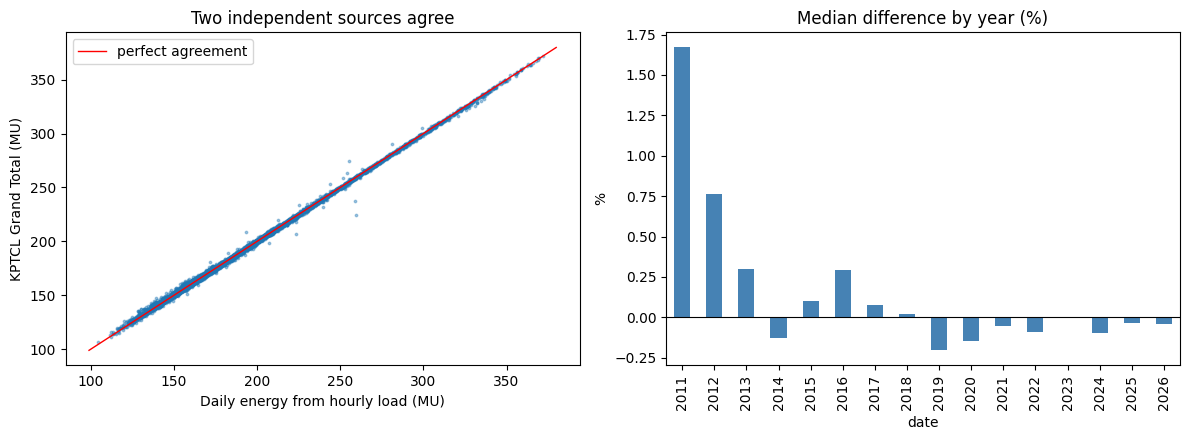

In [5]:
stations = pd.read_parquet(config.DATA_RAW / "kptcl-stations.parquet")
check = clean.crosscheck_daily(load, stations, log)   # days with >22 hours only

print(f"days compared: {len(check):,}")
print(f"correlation: {check.grand_total_mu.corr(check.hourly_mu):.4f}")
print(f"median difference: {check.diff_pct.median():+.2f}%   |  days within ±2%: {(check.diff_pct.abs() <= 2).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(check.hourly_mu, check.grand_total_mu, s=3, alpha=0.4)
lim = [check[["grand_total_mu", "hourly_mu"]].min().min() * 0.95, check[["grand_total_mu", "hourly_mu"]].max().max() * 1.02]
axes[0].plot(lim, lim, color="red", lw=1, label="perfect agreement")
axes[0].set_xlabel("Daily energy from hourly load (MU)"); axes[0].set_ylabel("KPTCL Grand Total (MU)")
axes[0].set_title("Two independent sources agree"); axes[0].legend()
check.diff_pct.groupby(check.index.year).median().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Median difference by year (%)"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.savefig(config.FIGURES / "02_cross_check.png", dpi=120); plt.show()

In [6]:
# Days that disagree most — worth a look
check.reindex(check.diff_pct.abs().sort_values(ascending=False).index).head(8).round(2)

,grand_total_mu,hourly_mu,diff_pct,xcheck_flag
date,,,,
2023-11-26,224.13,259.21,-13.53,True
2023-11-19,237.20,258.82,-8.35,True
2023-11-14,208.98,193.52,7.99,True
2023-11-09,206.49,223.38,-7.56,True
2023-10-31,274.55,255.39,7.50,True
2011-08-15,147.58,139.26,5.98,True
2011-04-25,137.55,130.07,5.75,True
2011-08-04,135.15,128.23,5.40,True


_What I see:_ several of the worst days fall in **Oct–Nov 2023** — inside our critical window. Slice it
(Riley: "slice your data") to see if the key months are affected.

In [7]:
w = check[check.index.month.isin([8, 9, 10, 11, 12])]
print("Share of Aug–Dec days flagged (>3% disagreement), by year:")
print((w.groupby(w.index.year).xcheck_flag.mean() * 100).round(1).to_string())
w23 = check.loc["2023-08":"2023-12"]
print("\n2023 monthly mean / std of difference (%):")
print(w23.diff_pct.groupby(w23.index.month).agg(["mean", "std"]).round(2).to_string())

Share of Aug–Dec days flagged (>3% disagreement), by year:
date
2011    24.7
2012     0.0
2013     0.0
2014     0.0
2015     0.7
2016     0.7
2017     0.0
2018     0.0
2019     0.7
2020     0.0
2021     1.3
2022     0.0
2023     5.2
2024     0.0
2025     0.0
2026     0.0

2023 monthly mean / std of difference (%):
      mean   std
date            
8     0.11  0.22
9    -0.01  0.21
10    0.30  1.35
11   -0.65  3.73
12   -0.13  0.20


### Step 4.4 — Look at the cleaned series
*Why:* Riley: "look at your distributions" and "check for consistency over time". A picture catches problems
summary statistics hide.

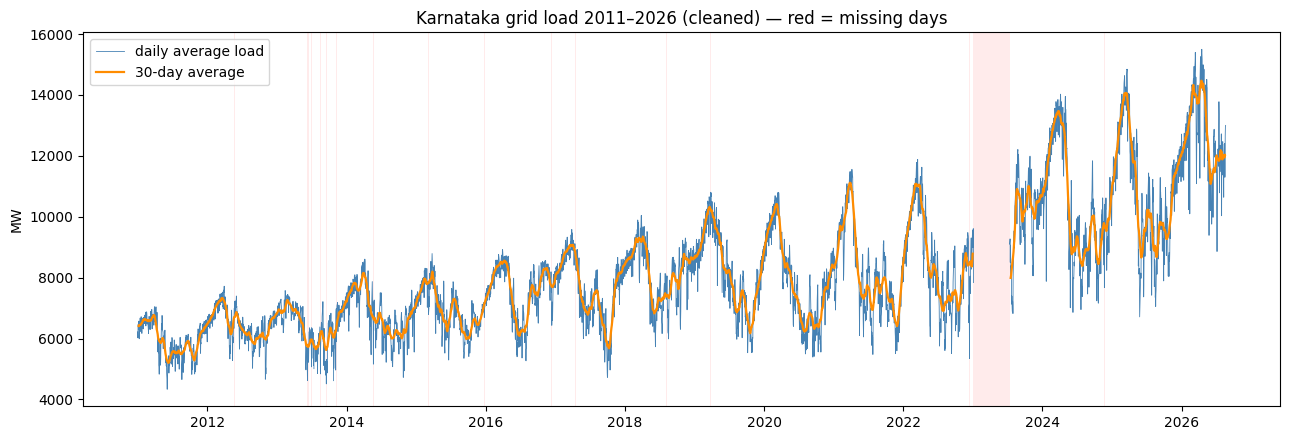

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
d = load.load_mw.resample("D").mean()
ax.plot(d.index, d.values, lw=0.6, color="steelblue", label="daily average load")
ax.plot(d.rolling(30, center=True, min_periods=20).mean(), color="darkorange", lw=1.6, label="30-day average")
gaps = load.is_missing.resample("D").mean() > 0.5
for day in d.index[gaps]:
    ax.axvspan(day, day + pd.Timedelta(days=1), color="red", alpha=0.08, lw=0)
ax.set_title("Karnataka grid load 2011–2026 (cleaned) — red = missing days")
ax.set_ylabel("MW"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(config.FIGURES / "02_clean_load_overview.png", dpi=120); plt.show()

### Step 4.5 — Generation by source
*Why:* station names change over the years, so we group them into sources (coal, hydro, solar, wind, gas,
central imports). Grouping rules are in `clean.SOURCE_GROUPS`.

In [9]:
gen = clean.clean_generation(stations, log)
gen.groupby(gen.index.year).mean().round(1)

,coal,gas,hydro,solar,wind,central_import,total
date,,,,,,,
2011,56.6,NaN,37.7,NaN,NaN,30.5,145.9
2012,70.4,NaN,29.9,NaN,NaN,32.7,157.0
2013,74.7,NaN,33.4,NaN,NaN,33.7,156.8
2014,78.0,NaN,37.2,0.2,9.4,38.5,165.7
2015,81.4,NaN,25.0,0.4,10.8,44.9,167.7
2016,74.5,NaN,16.7,0.7,12.1,54.7,183.2
2017,63.6,NaN,20.4,3.3,15.5,57.1,183.4
2018,56.4,NaN,29.1,17.1,22.6,53.3,197.2
2019,41.3,NaN,36.8,31.9,23.6,51.5,198.4


### Step 4.6 — Reservoirs, weather, holidays

In [10]:
res = clean.clean_reservoirs(pd.read_parquet(config.DATA_RAW / "kptcl-reservoirs.parquet"), log)
raw_res = pd.read_parquet(config.DATA_RAW / "kptcl-reservoirs.parquet")
print("storage % values above 110 (examples):")
print(raw_res.loc[raw_res.current_storage_percent > 110, ["report_date", "reservoir", "current_storage_percent"]].head())

wx = clean.clean_weather_daily(pd.read_csv(config.DATA_RAW / "weather_daily.csv"), log)
wxh = clean.clean_weather_hourly(pd.read_csv(config.DATA_RAW / "weather_hourly_bengaluru.csv"))
hol = pd.read_csv(config.DATA_RAW / "holidays_karnataka.csv", parse_dates=["date"])
print(f"\nweather daily: {wx.shape}, hourly Bengaluru: {wxh.shape}, holidays: {len(hol)}")
wx.describe().round(1)

storage % values above 110 (examples):
     report_date reservoir  current_storage_percent
3931  2022-07-02      Mani                7495.7525



weather daily: (5710, 12), hourly Bengaluru: (137040, 3), holidays: 365


,farm_rain_mm,farm_tmax_c,blr_rain_mm,blr_tmax_c,blr_tmin_c,rain_Raichur,rain_Kalaburagi,rain_Belagavi,rain_Mandya,rain_Davangere,rain_Tumakuru,rain_Hubballi
count,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0,5710.0
mean,2.8,30.6,2.7,28.7,18.8,2.3,2.5,3.9,2.7,2.6,2.8,2.7
std,4.5,3.3,5.7,3.0,2.3,5.7,6.1,8.8,5.5,5.6,5.7,6.1
min,0.0,22.5,0.0,18.3,9.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,0.0,28.2,0.0,26.6,17.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,0.6,29.6,0.2,27.9,19.4,0.0,0.0,0.2,0.2,0.1,0.2,0.1
75%,3.7,33.2,3.1,30.6,20.3,1.5,1.6,4.0,2.6,2.6,2.9,2.7
max,47.1,41.0,126.6,39.5,24.9,81.7,102.1,224.6,65.0,91.8,76.1,96.3


### Step 4.7 — Save clean tables and the validation log

In [11]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
outputs = {
    "load_hourly.parquet": load,
    "generation_daily.parquet": gen,
    "reservoirs_daily.parquet": res,
    "weather_daily.parquet": wx,
    "weather_hourly_blr.parquet": wxh,
    "holidays.parquet": hol,
    "daily_crosscheck.parquet": check,
}
for name, df in outputs.items():
    df.to_parquet(config.DATA_PROCESSED / name)
    print(f"saved {name:28s} {df.shape}")

vlog = log.to_frame()
vlog.to_csv(config.ROOT / "reports" / "validation_log.csv", index=False)
vlog

saved load_hourly.parquet          (137040, 3)
saved generation_daily.parquet     (5432, 7)


saved reservoirs_daily.parquet     (16296, 6)
saved weather_daily.parquet        (5710, 12)
saved weather_hourly_blr.parquet   (137040, 3)
saved holidays.parquet             (365, 2)
saved daily_crosscheck.parquet     (5431, 4)


,dataset,check,rows_affected,action
0,load,duplicate timestamps (hour-24 overlap),5344,kept the day's own hour-0 reading
1,load,...of which values disagree by >1 MW,101,kept hour-0 reading (documented)
2,load,"frequency outside (48.5, 51.5) Hz",3,set to NaN
3,load,frequency missing in raw,27,left as NaN
4,load,missing hours (gaps),6611,"kept as NaN, not filled"
5,load,isolated 1-hour spikes (>25% in and out),2,set to NaN
6,load,days where hourly vs Grand Total differ >3.0%,80,flagged (kept); excluded in robustness checks
7,generation,"duplicate (date, station) rows",38,kept first
8,generation,negative energy in 'coal',17,kept (auxiliary consumption when plant idle)
9,generation,negative energy in 'hydro',1,kept (auxiliary consumption when plant idle)


## 5. Result
| Expectation | What we found | ✓/✗ |
|---|---|---|
| ~5,400 duplicates from "hour 24" overlap, mostly identical | **5,344** duplicates, all hour-0/hour-24 pairs; **5,243 identical**, 101 differ (median 337 MW) | ✓ |
| Very few impossible values | 3 frequencies outside 48.5–51.5 Hz (e.g. 23 Hz), 2 isolated one-hour dips, 1 reservoir at 7,496% | ✓ |
| Known gaps | 6,611 missing hours (4.8%), mostly 3 Jan – 12 Jul 2023 | ✓ |
| Station names change | Yes — grouped into 7 sources (coal, gas, hydro, solar, wind, central imports, total) | ✓ |
| Hourly vs daily total agree within ~2% | **96.2% of days within ±2%**, correlation 0.9995 | ✓ |

**One surprise:** the few days where the two sources disagree by more than 3% cluster in **late Oct – Nov 2023** (8 days). However, **Aug and Sep 2023 — the main surge months — agree within ±0.2%**, and the hourly curves on the flagged days look normal. These days are **flagged, not removed**; Notebook 07 will test whether excluding them changes the answer.

**Clean outputs (`data/processed/`):** `load_hourly`, `generation_daily`, `reservoirs_daily`, `weather_daily`, `weather_hourly_blr`, `holidays`, `daily_crosscheck`.
**Validation log:** `reports/validation_log.csv` (every change, with row counts).
**Figures:** `02_cross_check.png`, `02_clean_load_overview.png`.

## 6. Caveats
- The **duplicate rule** (prefer hour 0 over hour 24) is a judgement call; it affects only 101 hours out of 130,427 with data.
- **2011 is less reliable:** 25% of its Aug–Dec days disagree with the daily total by >3%. Later notebooks should treat 2011–2012 with care (or start key models from 2015).
- **Negative generation** values (17 coal, 1 hydro) were kept — they are plausibly plant self-consumption while idle, but not verified.
- **Solar and wind** are only reported separately from 25 Aug 2014; before that they are one combined line, so they are NaN.
- **Gas (Yelahanka plant)** appears only from 2024.
- Gaps were **not filled**. Any model must handle missing hours explicitly.

## 7. Next
**Notebook 03 — The 15-year story** (Description stage):
- How much did demand grow, and in which hours?
- How did the generation mix change (coal → solar → coal again)?
- Did the daily peak move from evening to morning?
- These give the context ("Situation") for the final report.